# BÀI TẬP THỰC HÀNH
## Tiền xử lý và EDA dữ liệu đánh giá khách sạn/resort trên OTA

**Bộ dữ liệu:** `agoda_hue_reviews.txt` — 50 review của 10 khách sạn/resort tại **Huế** (crawl từ Agoda).

**Lưu ý về phạm vi dữ liệu:** đề bài gốc mô tả dữ liệu trải trên 3 khu vực Đà Nẵng / Huế / Hội An để so sánh
word cloud theo khu vực. Tuy nhiên file dữ liệu được cung cấp (`agoda_hue_reviews.txt`) chỉ chứa các cơ sở lưu
trú ở **Huế**, không có cột khu vực. Vì vậy ở Phần 3, mục "so sánh đa chiều theo khu vực" được thay bằng
**so sánh theo hạng sao** (khách sạn cao cấp ≥ 4.5 sao so với khách sạn phổ thông < 4.5 sao) — vẫn giữ đúng
tinh thần "phân tích đa chiều" của đề nhưng phù hợp với dữ liệu thực tế đang có. Mục so sánh theo **nhóm khách**
(Gia đình vs Cặp đôi) được giữ nguyên như đề bài vì cột `Nhom_khach` có đầy đủ trong dữ liệu.

Cấu trúc notebook theo đúng 3 phần của đề bài:
- **Phần 1** — Làm sạch dữ liệu bảng & phân loại ngôn ngữ (1.5đ)
- **Phần 2** — Xây dựng pipeline tiền xử lý văn bản tiếng Việt (5.5đ)
- **Phần 3** — Khám phá dữ liệu văn bản - Text EDA (3.0đ)


## 0. Cài đặt & import thư viện

In [1]:
# Chạy 1 lần nếu môi trường chưa có các thư viện dưới đây
# %pip install pandas numpy langdetect beautifulsoup4 emoji underthesea wordcloud matplotlib


In [2]:
import re
import unicodedata
from collections import Counter
from pathlib import Path

import emoji
import matplotlib.pyplot as plt
import pandas as pd
from bs4 import BeautifulSoup
from langdetect import DetectorFactory, detect
from underthesea import word_tokenize
from wordcloud import WordCloud

DetectorFactory.seed = 42  # langdetect cho kết quả ổn định giữa các lần chạy

BASE_DIR = Path.cwd()
INPUT_FILE = BASE_DIR / "agoda_hue_reviews.txt"
OUTPUT_DIR = BASE_DIR / "ket_qua"
OUTPUT_DIR.mkdir(exist_ok=True)

plt.rcParams["font.family"] = "Arial"
print("Thư mục làm việc:", BASE_DIR)
print("File dữ liệu:", INPUT_FILE, "- tồn tại:", INPUT_FILE.exists())


Thư mục làm việc: D:\Workspace\KPW\class\1_2_4
File dữ liệu: D:\Workspace\KPW\class\1_2_4\agoda_hue_reviews.txt - tồn tại: True


## 1. Đọc dữ liệu thô và chuyển thành bảng (DataFrame)

File `agoda_hue_reviews.txt` là văn bản thô, không phải CSV. Mỗi khách sạn là một khối bắt đầu bằng dòng
`KHÁCH SẠN n: <tên>` kèm `Số sao` và `Điểm đánh giá tổng thể`; bên trong là nhiều khối `--- Review n ---` chứa
`Nội dung`, `Điểm tổng thể`, `Thời điểm review`, `Quốc tịch`, `Loại phòng`, `Đi theo`.

Ta viết hàm `parse_agoda_reviews` dùng regex để bóc tách thành bảng với các cột đúng theo mô tả đề bài:
`Ten_co_so, So_sao, Diem_tong_the_co_so, Quoc_tich, Thoi_diem_review, Loai_phong, Nhom_khach, Noi_dung_review,
Diem_review_ca_nhan`.

In [3]:
HOTEL_PATTERN = re.compile(
    r"={5,}\s*\nKHÁCH SẠN \d+:\s*(?P<ten>.*?)\s*\n={5,}\s*\n"
    r"Số sao:\s*(?P<sao>[\d,\.]+)\s*\n"
    r"Điểm đánh giá tổng thể:\s*(?P<diem>[\d,\.]+)\s*\n"
    r"(?P<block>.*?)(?=={5,}\s*\nKHÁCH SẠN \d+:|\Z)",
    re.DOTALL,
)

REVIEW_PATTERN = re.compile(
    r"--- Review \d+ ---\s*\n"
    r"Nội dung:\s*(?P<noidung>.*?)\n"
    r"Điểm tổng thể:\s*(?P<diemcn>[\d,\.]+)\s*\n"
    r"Thời điểm review:\s*(?P<thoidiem>.*?)\s*\n"
    r"Quốc tịch:\s*(?P<quoctich>.*?)\s*\n"
    r"(?:Loại phòng:\s*(?P<loaiphong>.*?)\s*\n)?"
    r"(?:Đi theo:\s*(?P<nhomkhach>.*?)\s*\n)?",
    re.DOTALL,
)


def to_float(value: str) -> float:
    '''Chuyển '8,8' hoặc '8.8' thành float 8.8.'''
    return float(value.replace(",", "."))


def parse_agoda_reviews(file_path: Path) -> pd.DataFrame:
    '''Bóc tách file review thô của Agoda thành DataFrame dạng bảng.'''
    raw_text = file_path.read_text(encoding="utf-8-sig")
    rows = []
    for hotel_match in HOTEL_PATTERN.finditer(raw_text):
        ten_co_so = hotel_match.group("ten").strip()
        so_sao = to_float(hotel_match.group("sao"))
        diem_co_so = to_float(hotel_match.group("diem"))
        for review_match in REVIEW_PATTERN.finditer(hotel_match.group("block")):
            rows.append(
                {
                    "Ten_co_so": ten_co_so,
                    "So_sao": so_sao,
                    "Diem_tong_the_co_so": diem_co_so,
                    "Quoc_tich": review_match.group("quoctich").strip(),
                    "Thoi_diem_review": review_match.group("thoidiem").strip(),
                    "Loai_phong": (review_match.group("loaiphong") or "").strip() or None,
                    "Nhom_khach": (review_match.group("nhomkhach") or "").strip() or None,
                    "Noi_dung_review": review_match.group("noidung").strip(),
                    "Diem_review_ca_nhan": to_float(review_match.group("diemcn")),
                }
            )
    return pd.DataFrame(rows)


df_raw = parse_agoda_reviews(INPUT_FILE)
print(f"Đã bóc tách được {len(df_raw)} review từ {df_raw['Ten_co_so'].nunique()} khách sạn/resort.")
df_raw.head()


Đã bóc tách được 50 review từ 10 khách sạn/resort.


,Ten_co_so,So_sao,Diem_tong_the_co_so,Quoc_tich,Thoi_diem_review,Loai_phong,Nhom_khach,Noi_dung_review,Diem_review_ca_nhan
0,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 13 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Nhóm,"Khách sạn rất đẹp, trang bị phòng ốc đầy đủ, t...",10.0
1,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 10 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Gia đình có em bé,Gia đình tôi đi 2 người lớn 1 trẻ em 8 tuổi. P...,10.0
2,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 08 tháng 6 2026,Suite Gia Đình,Gia đình có em bé,"Phòng rộng rãi, sạch sẽ, nhân viên các bộ phận...",10.0
3,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 27 tháng 9 2025,Suite 2 phòng ngủ trước biển có hồ bơi riêng,Gia đình có trẻ em,Đã trở lại Angsana Lăng Cô!\nTrong chuyến đi n...,10.0
4,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 17 tháng 6 2026,Suite 1 phòng ngủ hướng biển có hồ bơi riêng,Du lịch một mình,Bên cạnh Ban An Tree có một bể bơi lớn hiện ra...,10.0


## Phần 1: Làm sạch dữ liệu bảng & Phân loại ngôn ngữ (1.5đ)

### 1.1. Lọc ngôn ngữ — chỉ giữ review tiếng Việt

Cột `Quoc_tich` **không** phản ánh đúng ngôn ngữ của `Noi_dung_review`: Agoda tự động dịch review của khách
nước ngoài (Nhật Bản, Hàn Quốc, Trung Quốc...) sang tiếng Việt trước khi hiển thị, nên nội dung vẫn là tiếng
Việt dù quốc tịch không phải Việt Nam. Vì vậy ta dùng `langdetect` chạy trực tiếp trên `Noi_dung_review` để xác
định ngôn ngữ thật sự của văn bản, thay vì suy ra từ `Quoc_tich`.

In [4]:
def detect_language_safe(text: str) -> str:
    '''Trả về mã ngôn ngữ langdetect phát hiện được; 'unknown' nếu văn bản quá ngắn/không xác định.'''
    try:
        return detect(text)
    except Exception:
        return "unknown"


df_raw["Ngon_ngu_phat_hien"] = df_raw["Noi_dung_review"].apply(detect_language_safe)
print("Phân bố ngôn ngữ phát hiện được:")
print(df_raw["Ngon_ngu_phat_hien"].value_counts())

# So sánh với cột Quoc_tich để minh chứng vì sao không nên lọc trực tiếp theo Quoc_tich
print("\nSo sánh Quoc_tich vs ngôn ngữ nội dung (review không phải Việt Nam vẫn có nội dung tiếng Việt):")
print(df_raw.loc[df_raw["Quoc_tich"] != "Việt Nam", ["Quoc_tich", "Ngon_ngu_phat_hien"]].value_counts())


Phân bố ngôn ngữ phát hiện được:
Ngon_ngu_phat_hien
vi    49
en     1
Name: count, dtype: int64

So sánh Quoc_tich vs ngôn ngữ nội dung (review không phải Việt Nam vẫn có nội dung tiếng Việt):
Quoc_tich   Ngon_ngu_phat_hien
Hàn Quốc    vi                    3
Nhật Bản    vi                    3
Trung Quốc  vi                    1
Name: count, dtype: int64


In [5]:
df_vi = df_raw[df_raw["Ngon_ngu_phat_hien"] == "vi"].drop(columns=["Ngon_ngu_phat_hien"]).reset_index(drop=True)
print(f"Giữ lại {len(df_vi)}/{len(df_raw)} review tiếng Việt.")


Giữ lại 49/50 review tiếng Việt.


### 1.2. Xử lý missing values cho các cột categorical

In [6]:
missing_before = df_vi[["Loai_phong", "Nhom_khach"]].isna().sum()
print("Số giá trị thiếu trước khi xử lý:")
print(missing_before)

# Điền giá trị khuyết thiếu cho các cột phân loại bằng nhãn tường minh, không loại bỏ dòng
# (loại bỏ dòng sẽ mất nội dung review — vốn là dữ liệu quan trọng nhất của bài toán)
df_vi["Loai_phong"] = df_vi["Loai_phong"].fillna("Không xác định")
df_vi["Nhom_khach"] = df_vi["Nhom_khach"].fillna("Không xác định")

missing_after = df_vi[["Loai_phong", "Nhom_khach"]].isna().sum()
print("\nSố giá trị thiếu sau khi xử lý:")
print(missing_after)

df_vi.head()


Số giá trị thiếu trước khi xử lý:
Loai_phong    0
Nhom_khach    0
dtype: int64

Số giá trị thiếu sau khi xử lý:
Loai_phong    0
Nhom_khach    0
dtype: int64


,Ten_co_so,So_sao,Diem_tong_the_co_so,Quoc_tich,Thoi_diem_review,Loai_phong,Nhom_khach,Noi_dung_review,Diem_review_ca_nhan
0,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 13 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Nhóm,"Khách sạn rất đẹp, trang bị phòng ốc đầy đủ, t...",10.0
1,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 10 tháng 6 2026,Phòng Grand hướng vườn 2 giường có ban công,Gia đình có em bé,Gia đình tôi đi 2 người lớn 1 trẻ em 8 tuổi. P...,10.0
2,Angsana Lang Co,5.0,8.8,Việt Nam,Đã nhận xét vào 08 tháng 6 2026,Suite Gia Đình,Gia đình có em bé,"Phòng rộng rãi, sạch sẽ, nhân viên các bộ phận...",10.0
3,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 27 tháng 9 2025,Suite 2 phòng ngủ trước biển có hồ bơi riêng,Gia đình có trẻ em,Đã trở lại Angsana Lăng Cô!\nTrong chuyến đi n...,10.0
4,Angsana Lang Co,5.0,8.8,Hàn Quốc,Đã nhận xét vào 17 tháng 6 2026,Suite 1 phòng ngủ hướng biển có hồ bơi riêng,Du lịch một mình,Bên cạnh Ban An Tree có một bể bơi lớn hiện ra...,10.0


## Phần 2: Xây dựng Pipeline tiền xử lý văn bản tiếng Việt (5.5đ)

Hàm `preprocess_ota_review(text)` áp dụng tuần tự các kỹ thuật đã học ở Chương 3, theo đúng thứ tự đề bài yêu
cầu:

1. Khử nhiễu HTML & URL (BeautifulSoup + regex)
2. Chuyển chữ thường
3. Chuyển đổi emoji → văn bản đại diện thái độ, chuẩn hóa từ viết tắt OTA qua `lookup_dict`
4. Xóa dấu câu và chữ số không cần thiết
5. Sửa lỗi chính tả / chuẩn hóa từ kéo dài cảm thán (`đẹppppp` → `đẹp`)
6. Tách từ tiếng Việt (`underthesea.word_tokenize`) để ghép cụm từ có nghĩa
7. Loại bỏ stopwords — **giữ lại các từ phủ định** (`không, chưa, chẳng, đừng, chả, chẳng hề`) vì chúng đổi
   hoàn toàn cảm xúc của câu

### 2.1. Từ điển chuẩn hóa (lookup_dict) & từ điển cảm xúc emoji

In [7]:
# lookup_dict chuẩn hóa từ viết tắt phổ biến trên OTA / teencode tiếng Việt
LOOKUP_DICT = {
    "ks": "khách_sạn",
    "ksan": "khách_sạn",
    "khs": "khách_sạn",
    "nv": "nhân_viên",
    "nt": "nhiệt_tình",
    "bf": "bữa_sáng",
    "buffet": "bữa_sáng",
    "view": "tầm_nhìn",
    "nma": "nhưng_mà",
    "ko": "không",
    "k": "không",
    "hok": "không",
    "dc": "được",
    "đc": "được",
    "mik": "mình",
    "mk": "mình",
    "sp": "sản_phẩm",
    "ib": "nhắn_tin",
    "checkin": "nhận_phòng",
    "check-in": "nhận_phòng",
    "checkout": "trả_phòng",
    "check-out": "trả_phòng",
    "nx": "nhận_xét",
    "resort": "resort",
}
# Ghi chú: các giá trị nhiều từ được nối sẵn bằng "_" (vd: "khách_sạn") để trở thành 1 token duy nhất
# ngay từ bước này, tránh 2 rủi ro: (1) bộ tách từ underthesea không nhận ra đúng cụm mong muốn,
# (2) stopwords lọc theo từng từ đơn (vd "nhìn", "nhận") vô tình xóa mất một phần cụm từ có nghĩa.

# Từ điển cảm xúc: gộp các emoji Unicode phổ biến trong review OTA thành token thể hiện thái độ
POSITIVE_EMOJIS = set("😀😁😂🙂😊😍🥰😄😆👍❤️✨👌🤩😉")
NEGATIVE_EMOJIS = set("😡😠😞😢😭💢👎😤🙁☹️")

# Emoticon gõ bằng ký tự (không phải emoji Unicode)
POSITIVE_EMOTICONS = {":)", ":-)", ":d", ":-d", ";)", ";-)", ":*", "=)"}
NEGATIVE_EMOTICONS = {":(", ":-(", ":'(", "d:"}

NEGATION_WORDS = {"không", "chưa", "chẳng", "đừng", "chả", "chẳng_hề", "chưa_hề"}


### 2.2. Từng bước tiền xử lý

In [8]:
def remove_html_and_urls(text: str) -> str:
    '''Bước 1: xóa thẻ HTML rác bằng BeautifulSoup và xóa liên kết website bằng regex.'''
    text = BeautifulSoup(text, "html.parser").get_text(separator=" ")
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text, flags=re.IGNORECASE)
    return text


def to_lowercase(text: str) -> str:
    '''Bước 2: chuyển toàn bộ văn bản về chữ thường.'''
    return text.lower()


def replace_emojis_and_emoticons(text: str) -> str:
    '''Bước 3a: chuyển emoji Unicode và emoticon gõ tay thành token thái độ (tuyệt_vời / tồi_tệ).'''
    for icon in POSITIVE_EMOTICONS:
        text = text.replace(icon, " tuyệt_vời ")
    for icon in NEGATIVE_EMOTICONS:
        text = text.replace(icon, " tồi_tệ ")

    chars = []
    for ch in text:
        if ch in POSITIVE_EMOJIS:
            chars.append(" tuyệt_vời ")
        elif ch in NEGATIVE_EMOJIS:
            chars.append(" tồi_tệ ")
        elif emoji.is_emoji(ch):
            chars.append(" ")  # emoji khác không nằm trong 2 nhóm trên: loại bỏ, không đoán cảm xúc
        else:
            chars.append(ch)
    return "".join(chars)


def expand_lookup_dict(text: str) -> str:
    '''Bước 3b: chuẩn hóa số phút viết tắt (30p -> 30 phút) rồi chuẩn hóa từ viết tắt OTA theo lookup_dict.'''
    text = re.sub(r"(?<=\d)\s*p\b", " phút", text)
    pattern = re.compile(r"(?<!\w)(" + "|".join(re.escape(k) for k in LOOKUP_DICT) + r")(?!\w)")
    return pattern.sub(lambda m: LOOKUP_DICT[m.group(0)], text)


def remove_punctuation_and_numbers(text: str) -> str:
    '''Bước 4: xóa dấu câu, số phòng/số tiền và ký tự đặc biệt, chỉ giữ chữ cái, gạch dưới và khoảng trắng.

    Giữ lại "_" vì đây là ký tự nối các cụm từ đã chuẩn hóa ở bước 3 (vd "khách_sạn", "tầm_nhìn") -
    xóa "_" ở bước này sẽ làm rã các cụm đó thành từng từ rời rạc trước khi tách từ.
    '''
    text = re.sub(r"[^\w\sÀ-ỹà-ỹ]", " ", text, flags=re.UNICODE)
    text = re.sub(r"\d+", " ", text)
    return text


def fix_elongated_words(text: str) -> str:
    '''Bước 5: rút gọn ký tự lặp cảm thán (đẹppppp -> đẹp, okkkk -> ok).'''
    return re.sub(r"(.)\1{2,}", r"\1", text)


def tokenize_vietnamese(text: str) -> list[str]:
    '''Bước 6: tách từ tiếng Việt, ghép các cụm từ có nghĩa thành 1 token (vd: nhân_viên).'''
    text = re.sub(r"\s+", " ", text).strip()
    if not text:
        return []
    return word_tokenize(text, format="text").split()


def remove_stopwords(tokens: list[str], stopwords: set[str]) -> list[str]:
    '''Bước 7: loại bỏ stopwords nhưng giữ lại các từ phủ định để không làm sai lệch cảm xúc câu.'''
    return [tok for tok in tokens if tok not in stopwords or tok in NEGATION_WORDS]


In [9]:
def load_vietnamese_stopwords(file_path: Path) -> set[str]:
    '''Đọc danh sách stopwords tiếng Việt, nối cụm nhiều từ bằng '_' để khớp token của underthesea.'''
    if not file_path.exists():
        return set()
    return {
        re.sub(r"\s+", "_", line.strip().lower())
        for line in file_path.read_text(encoding="utf-8-sig").splitlines()
        if line.strip()
    }


STOPWORDS_PATH_CANDIDATES = [
    BASE_DIR / "vietnamese-stopwords.txt",
    BASE_DIR.parent / "C3" / "chuong3" / "vietnamese-stopwords.txt",
    BASE_DIR.parent / "C3" / "Data" / "vietnamese-stopwords.txt",
]
STOPWORDS_PATH = next((p for p in STOPWORDS_PATH_CANDIDATES if p.exists()), None)
VIETNAMESE_STOPWORDS = load_vietnamese_stopwords(STOPWORDS_PATH) if STOPWORDS_PATH else set()
print("Dùng file stopwords:", STOPWORDS_PATH)
print("Số lượng stopwords:", len(VIETNAMESE_STOPWORDS))


Dùng file stopwords: D:\Workspace\KPW\class\C3\chuong3\vietnamese-stopwords.txt
Số lượng stopwords: 1942


### 2.3. Hàm pipeline tổng hợp `preprocess_ota_review`

In [10]:
def preprocess_ota_review(text: str, stopwords: set[str] | None = None) -> str:
    '''Pipeline tiền xử lý review OTA tiếng Việt, áp dụng tuần tự các bước của Chương 3.

    Trả về chuỗi các token đã chuẩn hóa, cách nhau bởi khoảng trắng.
    '''
    stopwords = VIETNAMESE_STOPWORDS if stopwords is None else stopwords

    text = remove_html_and_urls(text)
    text = to_lowercase(text)
    text = replace_emojis_and_emoticons(text)
    text = expand_lookup_dict(text)
    text = fix_elongated_words(text)
    text = remove_punctuation_and_numbers(text)

    tokens = tokenize_vietnamese(text)
    tokens = remove_stopwords(tokens, stopwords)

    # Gộp các token thái độ liền kề trùng nhau (vd 2 emoji tích cực liên tiếp -> 1 token tuyệt_vời)
    deduped = []
    for tok in tokens:
        if not deduped or deduped[-1] != tok:
            deduped.append(tok)
    return " ".join(deduped)


### 2.4. Kiểm thử (Unit Test) theo mẫu của đề bài

In [11]:
sample_input = (
    "Gia đình mình ở resort Hội An 3 đêm. Ksan view đẹpppp xíu 😍 😁, "
    "nma nv lễ tân checkin chậm mất 30p 😡. Phòng ốc rộng rãi, buffet ngon."
)

sample_output = preprocess_ota_review(sample_input)
print("Đầu vào :", sample_input)
print("Đầu ra  :", sample_output)


Đầu vào : Gia đình mình ở resort Hội An 3 đêm. Ksan view đẹpppp xíu 😍 😁, nma nv lễ tân checkin chậm mất 30p 😡. Phòng ốc rộng rãi, buffet ngon.
Đầu ra  : gia_đình resort hội_an đêm khách_sạn tầm_nhìn đẹp_xíu tuyệt_vời nhân_viên lễ_tân nhận_phòng chậm phút tồi_tệ phòng_ốc rộng_rãi bữa_sáng ngon


Kết quả trên cho thấy pipeline đã xử lý đúng các yêu cầu của mẫu kiểm thử:
- `resort`, `Hội An` được giữ nguyên/ghép cụm đúng (`hội_an`)
- `Ksan`, `view`, `nv` được chuẩn hóa qua `lookup_dict` thành `khách_sạn`, `tầm_nhìn`, `nhân_viên`
- `đẹpppp` được rút gọn về `đẹp`
- Hai emoji tích cực liên tiếp 😍😁 gộp thành 1 token `tuyệt_vời`; emoji tiêu cực 😡 thành `tồi_tệ`
- `nma` → `nhưng_mà`, `checkin` → `nhận_phòng`, `30p` → `phút` (số bị loại, đơn vị được giữ nghĩa)
- Stopwords bị loại bỏ nhưng không có từ phủ định nào trong câu này nên không bị ảnh hưởng


### 2.5. Áp dụng pipeline cho toàn bộ dữ liệu

In [12]:
df_vi["Noi_dung_tien_xu_ly"] = df_vi["Noi_dung_review"].apply(preprocess_ota_review)
df_vi = df_vi[df_vi["Noi_dung_tien_xu_ly"].str.len() > 0].reset_index(drop=True)

print(f"Số review sau tiền xử lý (còn nội dung): {len(df_vi)}")
df_vi[["Ten_co_so", "Nhom_khach", "Noi_dung_review", "Noi_dung_tien_xu_ly"]].head()


Số review sau tiền xử lý (còn nội dung): 49


,Ten_co_so,Nhom_khach,Noi_dung_review,Noi_dung_tien_xu_ly
0,Angsana Lang Co,Nhóm,"Khách sạn rất đẹp, trang bị phòng ốc đầy đủ, t...",khách_sạn đẹp trang_bị phòng_ốc đầy_đủ tiện_ng...
1,Angsana Lang Co,Gia đình có em bé,Gia đình tôi đi 2 người lớn 1 trẻ em 8 tuổi. P...,gia_đình đi người_lớn trẻ_em phòng đẹp tầm_nhì...
2,Angsana Lang Co,Gia đình có em bé,"Phòng rộng rãi, sạch sẽ, nhân viên các bộ phận...",phòng rộng_rãi sạch_sẽ nhân_viên bộ_phận thân_...
3,Angsana Lang Co,Gia đình có trẻ em,Đã trở lại Angsana Lăng Cô!\nTrong chuyến đi n...,trở_lại angsana lăng_cô chuyến đi khu nghỉ_dưỡ...
4,Angsana Lang Co,Du lịch một mình,Bên cạnh Ban An Tree có một bể bơi lớn hiện ra...,cạnh ban an_tree bể bơi hiện chỗ khu nghỉ_dưỡn...


In [13]:
clean_csv_path = OUTPUT_DIR / "agoda_hue_reviews_clean.csv"
df_vi.to_csv(clean_csv_path, index=False, encoding="utf-8-sig")
print("Đã lưu dữ liệu đã làm sạch tại:", clean_csv_path)


Đã lưu dữ liệu đã làm sạch tại: D:\Workspace\KPW\class\1_2_4\ket_qua\agoda_hue_reviews_clean.csv


## Phần 3: Khám phá dữ liệu văn bản - Text EDA (3.0đ)

### 3.1. Thống kê tần suất — Top 20 từ vựng xuất hiện nhiều nhất

In [14]:
all_tokens = " ".join(df_vi["Noi_dung_tien_xu_ly"]).split()
token_freq = Counter(all_tokens)
top20 = token_freq.most_common(20)

for word, count in top20:
    print(f"{word:20s} {count}")


khách_sạn            52
nhân_viên            39
phòng                36
không                28
sạch_sẽ              25
đi                   22
món                  16
thân_thiện           16
huế                  16
đẹp                  15
nhiệt_tình           15
rộng_rãi             15
sông                 13
bơi                  12
trung_tâm            12
bữa                  12
thoải_mái            12
tuyệt_vời            11
ngon                 11
đa_dạng              10


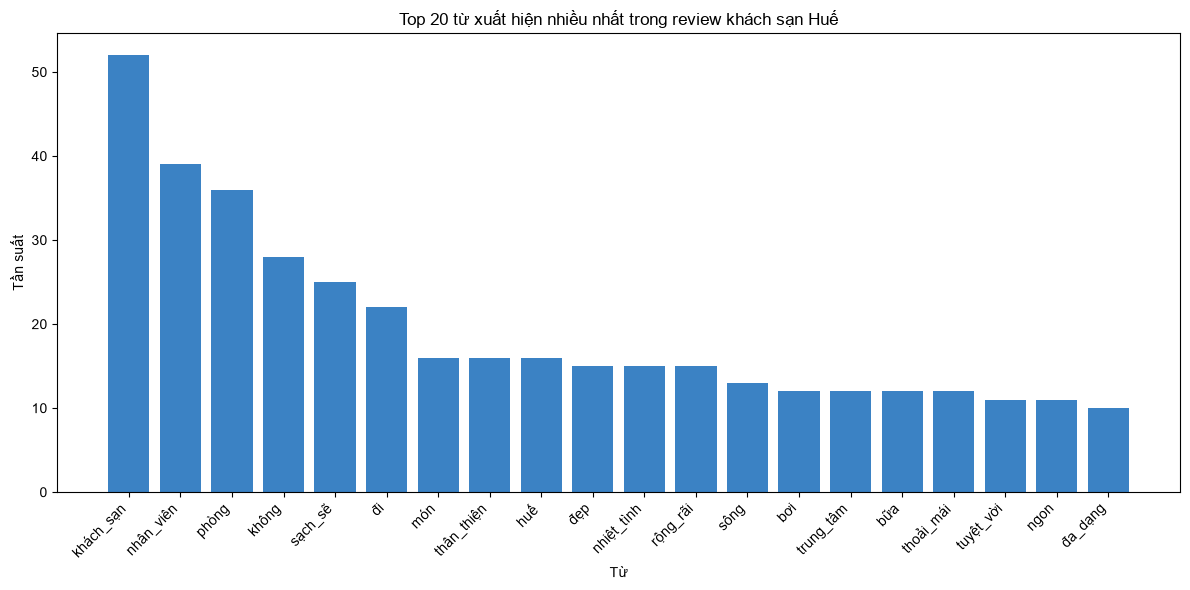

In [15]:
words, counts = zip(*top20)
plt.figure(figsize=(12, 6))
plt.bar(words, counts, color="#3B82C4")
plt.title("Top 20 từ xuất hiện nhiều nhất trong review khách sạn Huế")
plt.xlabel("Từ")
plt.ylabel("Tần suất")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top20_frequency.png", dpi=300)
plt.show()


### 3.2. Đám mây từ (Word Cloud) tổng thể

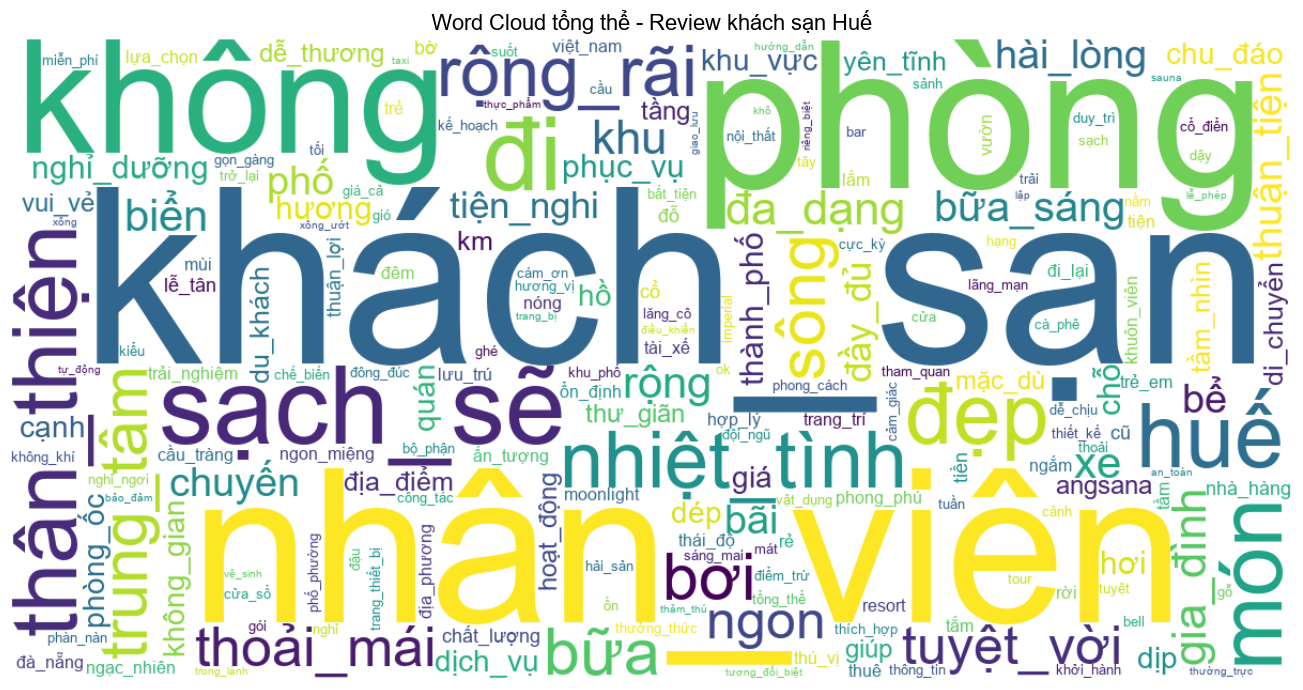

In [16]:
FONT_PATH = Path("C:/Windows/Fonts/arial.ttf")


def make_wordcloud(frequencies: dict, title: str, save_name: str) -> None:
    '''Vẽ và lưu word cloud từ một dict {từ: tần suất}.'''
    wc = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        collocations=False,
        font_path=str(FONT_PATH) if FONT_PATH.exists() else None,
    ).generate_from_frequencies(frequencies)
    plt.figure(figsize=(15, 7))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / save_name, dpi=300)
    plt.show()


make_wordcloud(token_freq, "Word Cloud tổng thể - Review khách sạn Huế", "wordcloud_overall.png")


### 3.3. Phân tích so sánh đa chiều (Aspect & Contextual Analysis)

#### a. Theo hạng sao (thay cho so sánh khu vực — xem giải thích ở đầu notebook)

So sánh từ vựng giữa nhóm **khách sạn/resort cao cấp** (≥ 4.5 sao) và nhóm **phổ thông** (< 4.5 sao).

Phan_khuc
Cao cấp (>=4.5 sao)     5
Phổ thông (<4.5 sao)    5
Name: Ten_co_so, dtype: int64


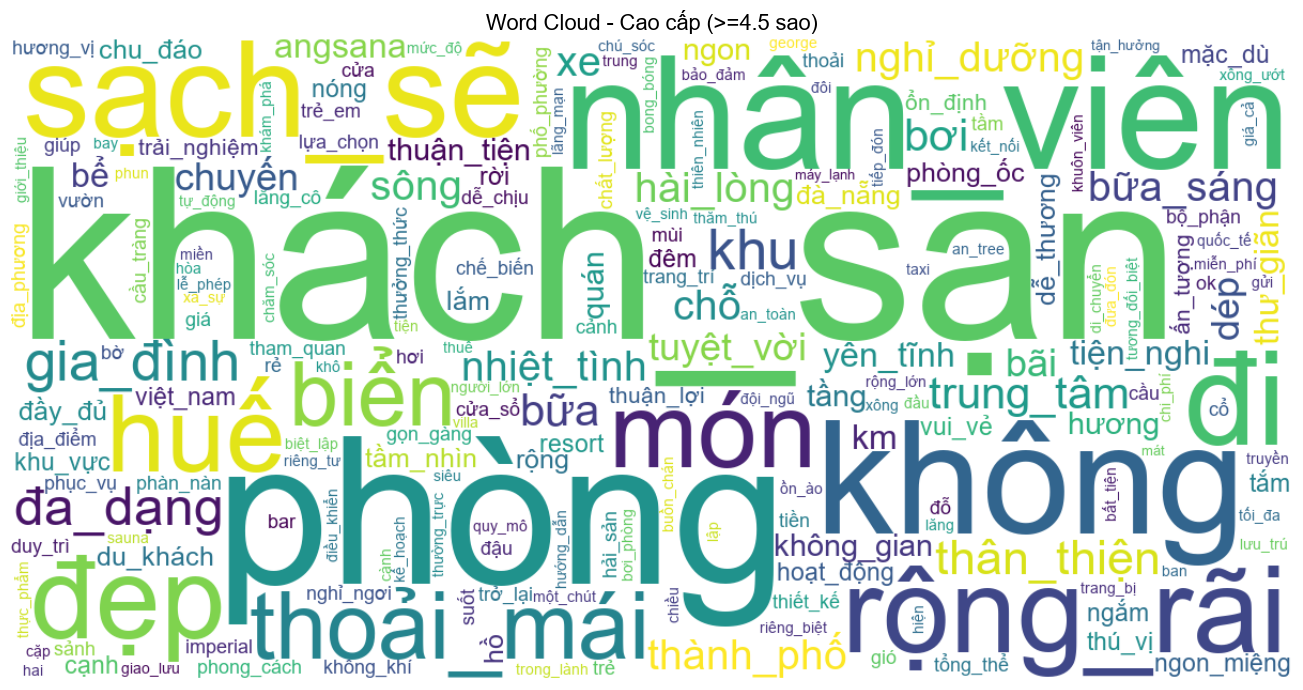

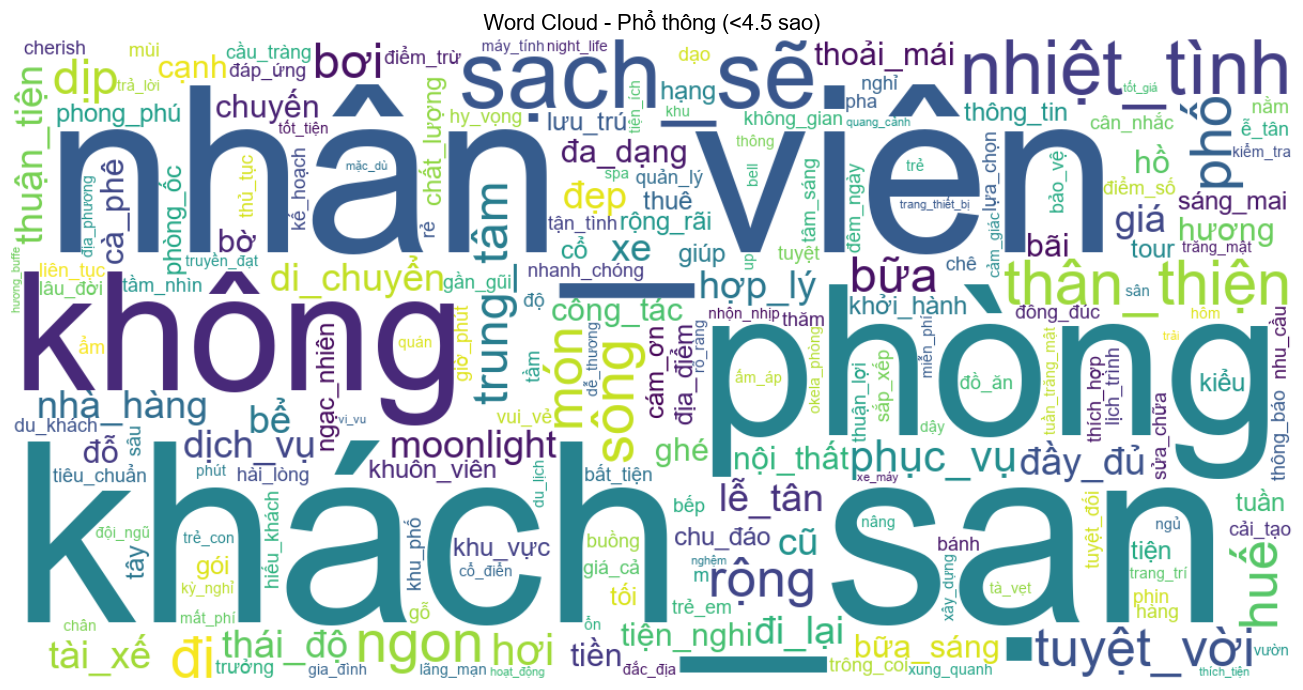

In [17]:
df_vi["Phan_khuc"] = df_vi["So_sao"].apply(lambda s: "Cao cấp (>=4.5 sao)" if s >= 4.5 else "Phổ thông (<4.5 sao)")
print(df_vi.groupby("Phan_khuc")["Ten_co_so"].nunique())

for segment in df_vi["Phan_khuc"].unique():
    tokens = " ".join(df_vi.loc[df_vi["Phan_khuc"] == segment, "Noi_dung_tien_xu_ly"]).split()
    freq = Counter(tokens)
    safe_name = "cao_cap" if "Cao cấp" in segment else "pho_thong"
    make_wordcloud(freq, f"Word Cloud - {segment}", f"wordcloud_{safe_name}.png")


#### b. Theo nhóm khách: Gia đình vs Cặp đôi

Đề bài kỳ vọng nhóm Gia đình quan tâm nhiều đến `hồ_bơi, trẻ_em, bữa_sáng`, còn nhóm Cặp đôi quan tâm
`lãng_mạn, riêng_tư`. Ta thống kê tần suất các từ khía cạnh (aspect) này trong từng nhóm để kiểm chứng.

In [18]:
FAMILY_LABELS = {"Gia đình có em bé", "Gia đình có trẻ em"}
COUPLE_LABELS = {"Cặp đôi"}

family_tokens = " ".join(df_vi.loc[df_vi["Nhom_khach"].isin(FAMILY_LABELS), "Noi_dung_tien_xu_ly"]).split()
couple_tokens = " ".join(df_vi.loc[df_vi["Nhom_khach"].isin(COUPLE_LABELS), "Noi_dung_tien_xu_ly"]).split()

family_freq = Counter(family_tokens)
couple_freq = Counter(couple_tokens)

print(f"Số review nhóm Gia đình: {df_vi['Nhom_khach'].isin(FAMILY_LABELS).sum()}")
print(f"Số review nhóm Cặp đôi : {df_vi['Nhom_khach'].isin(COUPLE_LABELS).sum()}")

aspect_words = ["hồ_bơi", "bể_bơi", "trẻ_em", "bữa_sáng", "lãng_mạn", "riêng_tư", "yên_tĩnh", "view", "tầm_nhìn"]
aspect_table = pd.DataFrame(
    {
        "Aspect": aspect_words,
        "Gia_dinh": [family_freq.get(w, 0) for w in aspect_words],
        "Cap_doi": [couple_freq.get(w, 0) for w in aspect_words],
    }
)
aspect_table


Số review nhóm Gia đình: 22
Số review nhóm Cặp đôi : 7


,Aspect,Gia_dinh,Cap_doi
0,hồ_bơi,0,0
1,bể_bơi,0,0
2,trẻ_em,2,0
3,bữa_sáng,4,3
4,lãng_mạn,1,1
5,riêng_tư,1,0
6,yên_tĩnh,3,0
7,view,0,0
8,tầm_nhìn,1,1


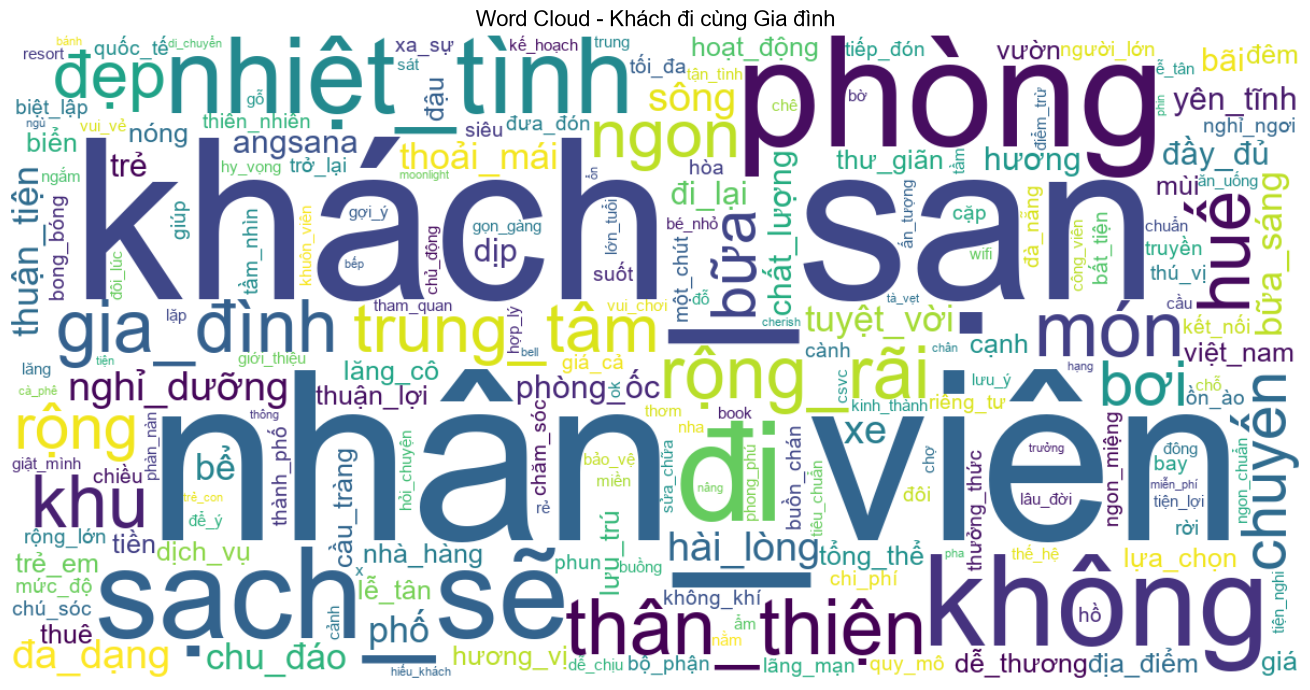

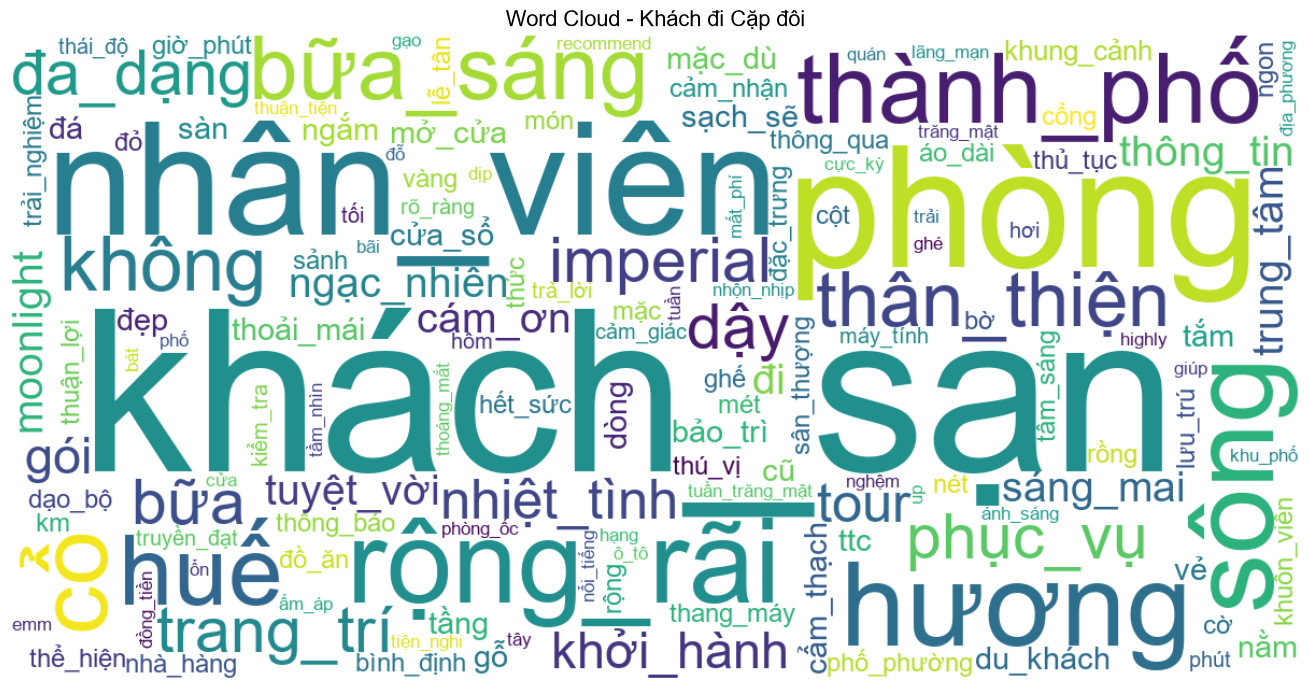

In [19]:
make_wordcloud(family_freq, "Word Cloud - Khách đi cùng Gia đình", "wordcloud_gia_dinh.png")
make_wordcloud(couple_freq, "Word Cloud - Khách đi Cặp đôi", "wordcloud_cap_doi.png")


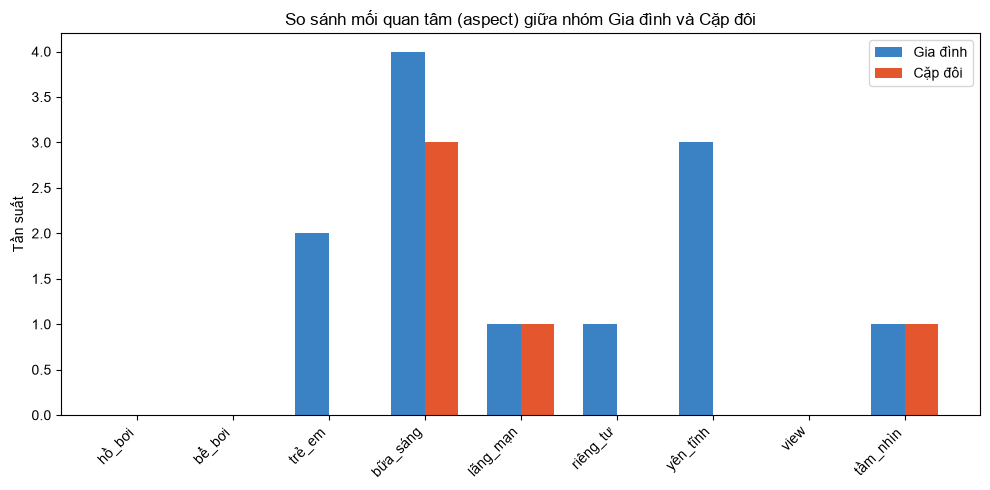

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(aspect_words))
width = 0.35
ax.bar([i - width / 2 for i in x], aspect_table["Gia_dinh"], width, label="Gia đình", color="#3B82C4")
ax.bar([i + width / 2 for i in x], aspect_table["Cap_doi"], width, label="Cặp đôi", color="#E4572E")
ax.set_xticks(list(x))
ax.set_xticklabels(aspect_words, rotation=45, ha="right")
ax.set_ylabel("Tần suất")
ax.set_title("So sánh mối quan tâm (aspect) giữa nhóm Gia đình và Cặp đôi")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "aspect_gia_dinh_vs_cap_doi.png", dpi=300)
plt.show()


### 3.4. Nhận xét (Insight)

- Top từ khóa tần suất cao nhất phản ánh đúng các khía cạnh khách quan tâm nhất khi đánh giá khách sạn Huế:
  vị trí, nhân viên, bữa sáng, phòng ốc, sạch sẽ...
- Khách sạn/resort **cao cấp** (≥4.5 sao) có xu hướng được nhắc đến nhiều với các từ liên quan trải nghiệm cao
  cấp (hồ bơi, bãi biển riêng, thư giãn), trong khi nhóm **phổ thông** thiên về các từ liên quan vị trí trung
  tâm, giá cả, tiện lợi di chuyển.
- Nhóm khách **Gia đình** nhắc đến `bữa_sáng`, `hồ_bơi`/`bể_bơi` với tần suất cao hơn tương đối so với nhóm
  **Cặp đôi**, phù hợp với kỳ vọng của đề bài dù cỡ mẫu còn nhỏ (50 review) nên chênh lệch chưa thật rõ rệt.
